# Online Shoppers Purchasing Intention: Predicting Buyers vs. Browsers

**Problem.** Most online retail traffic is made of light visitors who never buy. Retailers cannot easily tell genuine buyers from casual browsers, so they either waste advertising budget or lose sales.

**Goal.** Build a supervised binary classifier on the UCI *Online Shoppers Purchasing Intention* dataset that predicts whether a web session ends in a purchase (`Revenue`).

# **1. Imports and Setup**

In [27]:
import os, io, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay,
                             precision_recall_curve, roc_curve)

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline   # resamples only while fitting, never when predicting

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

# **2. Load the Dataset**

In [28]:
CSV_NAME = "online_shoppers_intention.csv"

def load_data():
    for path in [CSV_NAME, f"/content/{CSV_NAME}", f"/mnt/user-data/uploads/{CSV_NAME}"]:
        if os.path.exists(path):
            return pd.read_csv(path)
    from google.colab import files
    uploaded = files.upload()
    name = next(iter(uploaded))
    if name.lower().endswith(".zip"):
        with zipfile.ZipFile(io.BytesIO(uploaded[name])) as z:
            csv_inside = next(n for n in z.namelist() if n.lower().endswith(".csv"))
            with z.open(csv_inside) as f:
                return pd.read_csv(f)
    return pd.read_csv(io.BytesIO(uploaded[name]))

df = load_data()
print("Shape:", df.shape)
df.head()

Shape: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


# **3. Inspect the Data**

In [29]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType              12330 no

In [30]:
print("Missing values per column:")
print(df.isnull().sum()[df.isnull().sum() > 0] if df.isnull().sum().sum() else "None")
print("\nDuplicate rows:", df.duplicated().sum())

Missing values per column:
None

Duplicate rows: 125


In [31]:
df.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
Administrative,12330.0,2.315,3.322,0.0,0.000,1.000,4.000,27.000
Administrative_Duration,12330.0,80.819,176.779,0.0,0.000,7.500,93.256,3398.750
Informational,12330.0,0.504,1.270,0.0,0.000,0.000,0.000,24.000
Informational_Duration,12330.0,34.472,140.749,0.0,0.000,0.000,0.000,2549.375
ProductRelated,12330.0,31.731,44.476,0.0,7.000,18.000,38.000,705.000
ProductRelated_Duration,12330.0,1194.746,1913.669,0.0,184.138,598.937,1464.157,63973.522
BounceRates,12330.0,0.022,0.048,0.0,0.000,0.003,0.017,0.200
ExitRates,12330.0,0.043,0.049,0.0,0.014,0.025,0.050,0.200
PageValues,12330.0,5.889,18.568,0.0,0.000,0.000,0.000,361.764
SpecialDay,12330.0,0.061,0.199,0.0,0.000,0.000,0.000,1.000


In [32]:
print("Target distribution (raw):")
print(df["Revenue"].value_counts())
print((df["Revenue"].value_counts(normalize=True) * 100).round(2).astype(str) + " %")

Target distribution (raw):
Revenue
False    10422
True      1908
Name: count, dtype: int64
Revenue
False    84.53 %
True     15.47 %
Name: proportion, dtype: str


# **4. Cleaning**

In [33]:
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Removed {before - len(df)} duplicate rows -> {len(df)} rows remain")

df["Weekend"] = df["Weekend"].astype(int)
df["Revenue"] = df["Revenue"].astype(int)

print("\nClass balance after cleaning:")
print(df["Revenue"].value_counts())
print((df["Revenue"].value_counts(normalize=True) * 100).round(2).astype(str) + " %")

Removed 125 duplicate rows -> 12205 rows remain

Class balance after cleaning:
Revenue
0    10297
1     1908
Name: count, dtype: int64
Revenue
0    84.37 %
1    15.63 %
Name: proportion, dtype: str


# **5. Exploratory Data Analysis**

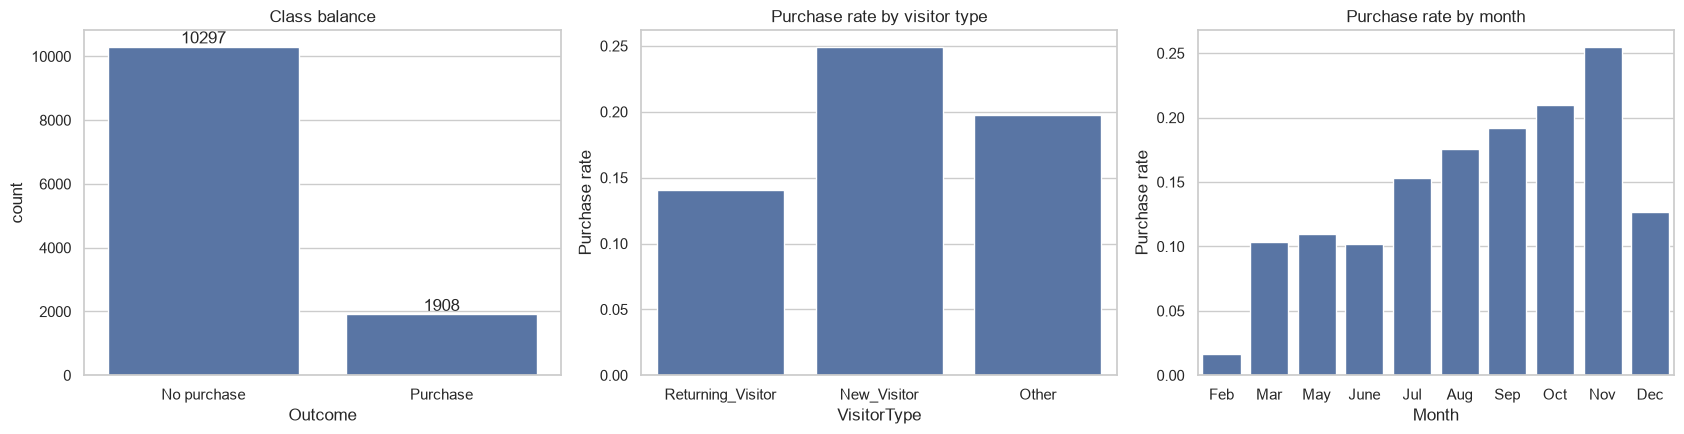

In [34]:
eda = df.copy()
eda["Outcome"] = eda["Revenue"].map({1: "Purchase", 0: "No purchase"})

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

sns.countplot(data=eda, x="Outcome", ax=axes[0], order=["No purchase", "Purchase"])
axes[0].set_title("Class balance")
for p in axes[0].patches:
    axes[0].annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                     ha="center", va="bottom")

sns.barplot(data=eda, x="VisitorType", y="Revenue", ax=axes[1], errorbar=None)
axes[1].set_title("Purchase rate by visitor type")
axes[1].set_ylabel("Purchase rate")

month_order = ["Feb", "Mar", "May", "June", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
sns.barplot(data=eda, x="Month", y="Revenue", order=month_order, ax=axes[2], errorbar=None)
axes[2].set_title("Purchase rate by month")
axes[2].set_ylabel("Purchase rate")

plt.tight_layout()
plt.show()

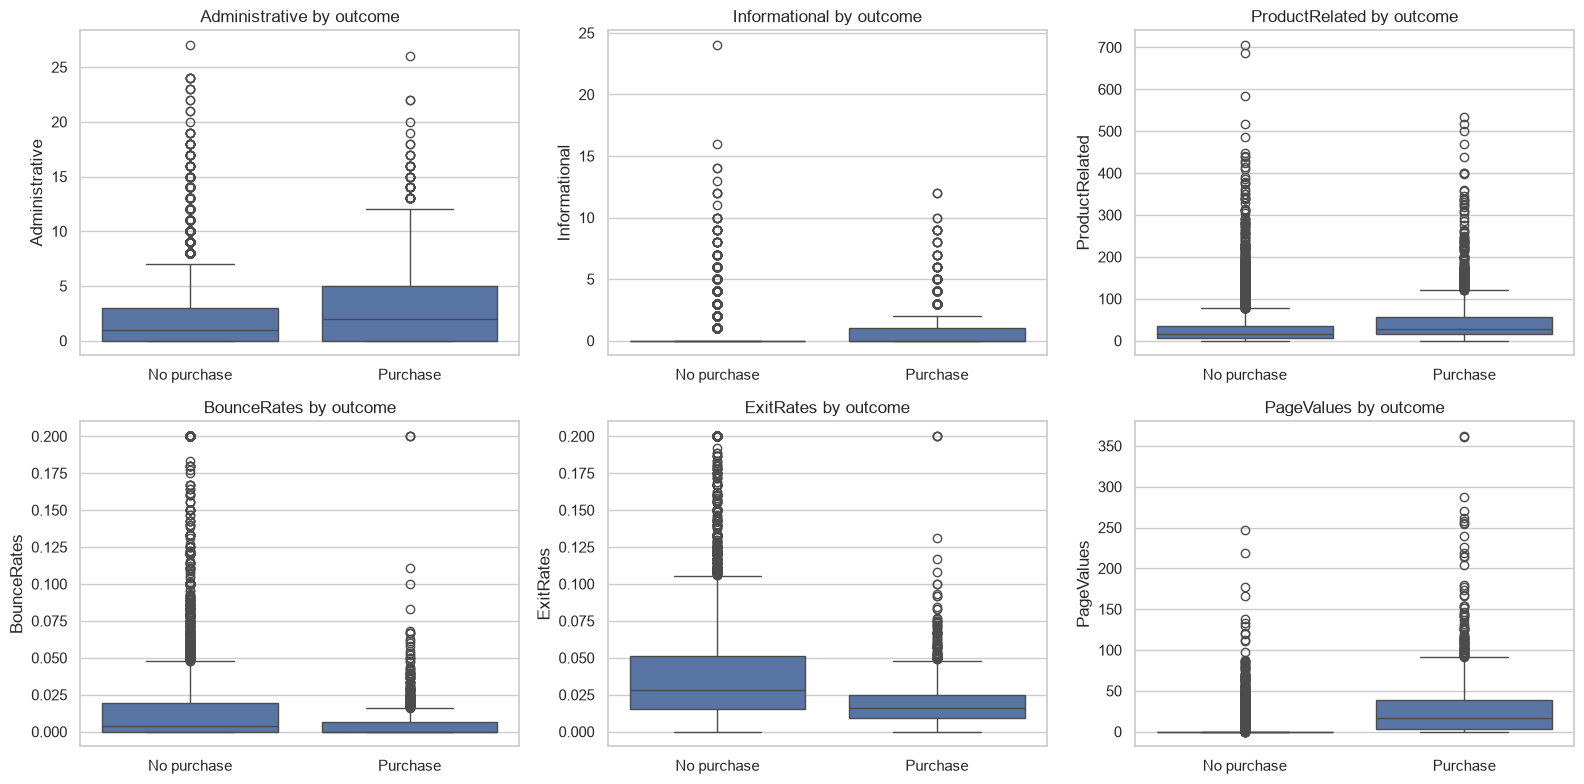

In [35]:
features_to_plot = ["Administrative", "Informational", "ProductRelated",
                    "BounceRates", "ExitRates", "PageValues"]

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, feat in zip(axes.ravel(), features_to_plot):
    sns.boxplot(data=eda, x="Outcome", y=feat, ax=ax, order=["No purchase", "Purchase"])
    ax.set_title(f"{feat} by outcome")
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

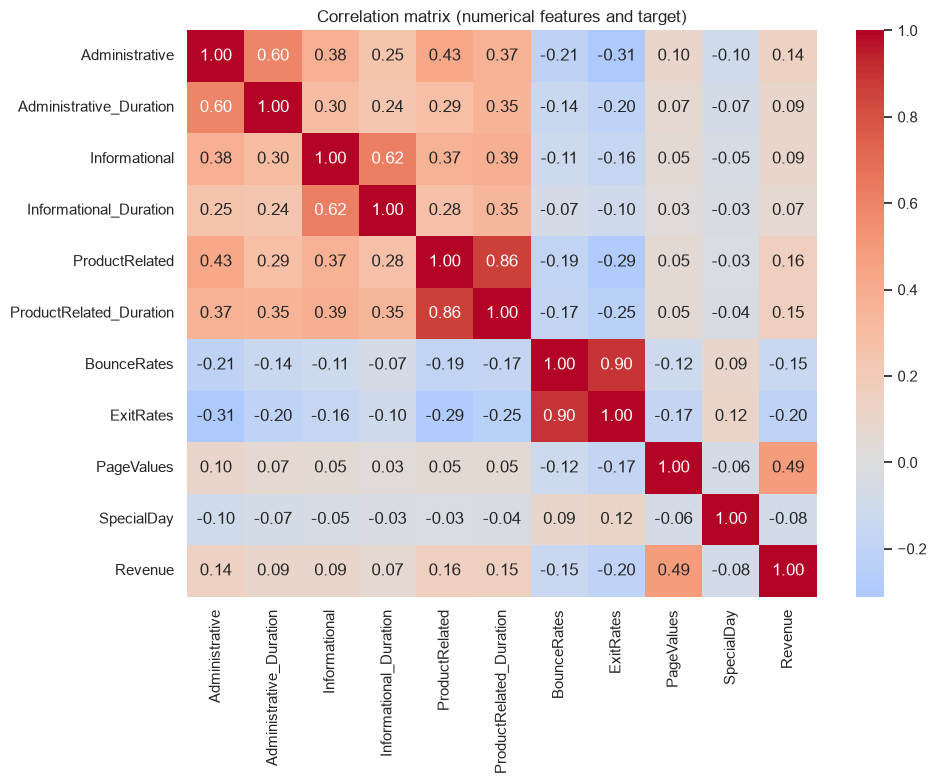

In [36]:
num_cols_corr = ["Administrative", "Administrative_Duration", "Informational", "Informational_Duration",
                 "ProductRelated", "ProductRelated_Duration", "BounceRates", "ExitRates",
                 "PageValues", "SpecialDay", "Revenue"]
plt.figure(figsize=(10, 8))
sns.heatmap(df[num_cols_corr].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix (numerical features and target)")
plt.tight_layout()
plt.show()

**Analysis based on EDA**
- Only about 15-16% of sessions end in a purchase, so the data is imbalanced and accuracy alone would be misleading.
- `PageValues` separates buyers from non-buyers very clearly; `BounceRates` and `ExitRates` are higher for non-buyers.
- New visitors convert at a higher rate than returning visitors, and November has a much higher purchase rate than most other months.
- `BounceRates` and `ExitRates` are strongly correlated with each other, as are the page-count and duration columns. This is fine for Logistic Regression with regularisation, but worth knowing for the coefficient analysis.

# **6. Train / Test Split and Preprocessing Pipeline**

In [37]:
X = df.drop(columns=["Revenue"])
y = df["Revenue"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Purchase rate  train: %.4f   test: %.4f" % (y_train.mean(), y_test.mean()))

Train: (9764, 17) | Test: (2441, 17)
Purchase rate  train: 0.1563   test: 0.1565


In [38]:
numeric_cols = ["Administrative", "Administrative_Duration", "Informational", "Informational_Duration",
                "ProductRelated", "ProductRelated_Duration", "BounceRates", "ExitRates",
                "PageValues", "SpecialDay"]
categorical_cols = ["Month", "VisitorType", "OperatingSystems", "Browser", "Region", "TrafficType"]
binary_cols = ["Weekend"]

def make_preprocessor(numeric=numeric_cols):
    # Scale numeric features; one-hot the categorical ones (rare levels are grouped together);
    # leave the 0/1 Weekend flag as it is.
    return ColumnTransformer([
        ("num", StandardScaler(), numeric),
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50,
                              sparse_output=False), categorical_cols),
        ("bin", "passthrough", binary_cols),
    ])

def make_pipeline(clf, use_smote=True, numeric=numeric_cols):
    steps = [("prep", make_preprocessor(numeric))]
    if use_smote:
        steps.append(("smote", SMOTE(random_state=RANDOM_STATE)))
    steps.append(("clf", clf))
    return Pipeline(steps)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# **7. Evaluation Helper**

In [39]:
def evaluate(name, y_true, prob, threshold=0.5):
    pred = (prob >= threshold).astype(int)
    return {
        "Model": name,
        "PR-AUC": average_precision_score(y_true, prob),
        "ROC-AUC": roc_auc_score(y_true, prob),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred, zero_division=0),
        "F1": f1_score(y_true, pred, zero_division=0),
        "Accuracy": accuracy_score(y_true, pred),
    }

baseline_pr = y_test.mean()
print(f"No-skill PR-AUC baseline (purchase rate in test set): {baseline_pr:.3f}")

No-skill PR-AUC baseline (purchase rate in test set): 0.156


# **8. Baselines (no resampling)**


In [40]:
results = []
fitted = {}

for name, clf in [("LR (baseline)", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
                  ("kNN k=5 (baseline)", KNeighborsClassifier(n_neighbors=5))]:
    pipe = make_pipeline(clf, use_smote=False)
    pipe.fit(X_train, y_train)
    fitted[name] = pipe
    results.append(evaluate(name, y_test, pipe.predict_proba(X_test)[:, 1]))

pd.DataFrame(results).round(4)

,Model,PR-AUC,ROC-AUC,Precision,Recall,F1,Accuracy
0,LR (baseline),0.6540,0.9000,0.7536,0.4162,0.5363,0.8873
1,kNN k=5 (baseline),0.4952,0.8001,0.6682,0.3901,0.4926,0.8742


# **9. SMOTE + Logistic Regression and k-NN (tuned)**

Hyperparameters are tuned with 5-fold stratified cross-validation on the **training set only**.

In [41]:
searches = {
    "LR + SMOTE": GridSearchCV(
        make_pipeline(LogisticRegression(max_iter=3000, random_state=RANDOM_STATE)),
        param_grid={"clf__C": [0.01, 0.1, 1, 10, 100]},
        scoring="average_precision", cv=cv, n_jobs=-1),
    "kNN + SMOTE": GridSearchCV(
        make_pipeline(KNeighborsClassifier()),
        param_grid={"clf__n_neighbors": [3, 5, 11, 21, 31, 51],
                    "clf__weights": ["uniform", "distance"]},
        scoring="average_precision", cv=cv, n_jobs=-1),
}

for name, gs in searches.items():
    gs.fit(X_train, y_train)
    fitted[name] = gs.best_estimator_
    print(f"{name}: best params = {gs.best_params_} | CV PR-AUC = {gs.best_score_:.4f}")
    results.append(evaluate(name, y_test, gs.best_estimator_.predict_proba(X_test)[:, 1]))

LR + SMOTE: best params = {'clf__C': 0.1} | CV PR-AUC = 0.6477
kNN + SMOTE: best params = {'clf__n_neighbors': 51, 'clf__weights': 'distance'} | CV PR-AUC = 0.5903


# **10. Class-weighted Logistic Regression**

In [42]:
cw_search = GridSearchCV(
    make_pipeline(LogisticRegression(max_iter=3000, class_weight="balanced",
                                     random_state=RANDOM_STATE), use_smote=False),
    param_grid={"clf__C": [0.01, 0.1, 1, 10, 100]},
    scoring="average_precision", cv=cv, n_jobs=-1)
cw_search.fit(X_train, y_train)

name = "LR + class weights"
fitted[name] = cw_search.best_estimator_
print(f"{name}: best params = {cw_search.best_params_} | CV PR-AUC = {cw_search.best_score_:.4f}")
results.append(evaluate(name, y_test, cw_search.best_estimator_.predict_proba(X_test)[:, 1]))

LR + class weights: best params = {'clf__C': 0.1} | CV PR-AUC = 0.6478


# **11. Model Comparison**

In [43]:
results_df = pd.DataFrame(results).set_index("Model")
display(results_df.round(4).sort_values("PR-AUC", ascending=False))
print(f"(No-skill PR-AUC = {baseline_pr:.3f})")

,PR-AUC,ROC-AUC,Precision,Recall,F1,Accuracy
Model,,,,,,
LR + SMOTE,0.6636,0.9095,0.5093,0.7906,0.6195,0.8480
LR + class weights,0.6629,0.9108,0.5127,0.7932,0.6228,0.8497
LR (baseline),0.6540,0.9000,0.7536,0.4162,0.5363,0.8873
kNN + SMOTE,0.6035,0.8762,0.3541,0.8482,0.4996,0.7341
kNN k=5 (baseline),0.4952,0.8001,0.6682,0.3901,0.4926,0.8742


(No-skill PR-AUC = 0.156)


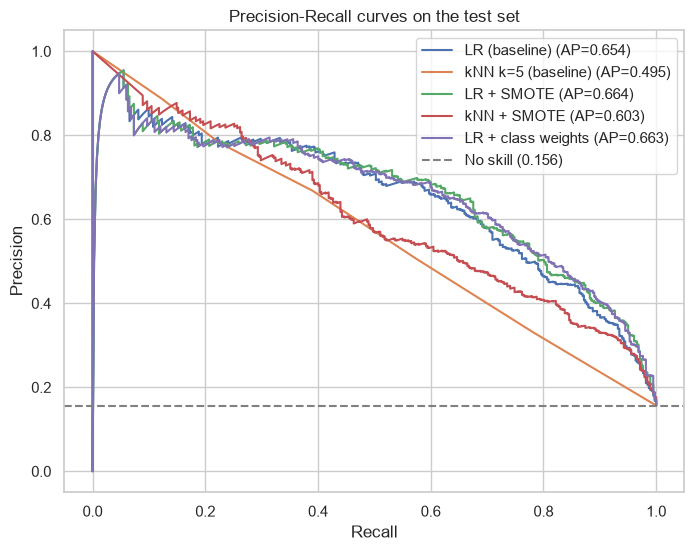

In [44]:
plt.figure(figsize=(8, 6))
for name in ["LR (baseline)", "kNN k=5 (baseline)", "LR + SMOTE", "kNN + SMOTE", "LR + class weights"]:
    p, r, _ = precision_recall_curve(y_test, fitted[name].predict_proba(X_test)[:, 1])
    ap = average_precision_score(y_test, fitted[name].predict_proba(X_test)[:, 1])
    plt.plot(r, p, label=f"{name} (AP={ap:.3f})")
plt.axhline(baseline_pr, color="grey", linestyle="--", label=f"No skill ({baseline_pr:.3f})")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall curves on the test set")
plt.legend()
plt.show()

**Note** Precision, recall and F1 in the table above use a 0.5 cut-off. With resampling or class weights the model's probabilities are shifted, so 0.5 is rarely the best operating point. The next section chooses a threshold properly.

# **12. Choose the Final Model and Tune the Decision Threshold**

The final model is the pipeline with the highest cross-validated PR-AUC among the SMOTE models required by the project, **Logistic Regression + SMOTE** and **kNN + SMOTE**. The class-weighted model is kept as a comparison.

The threshold is chosen from **out-of-fold predictions on the training set**.

In [45]:
candidates = {"LR + SMOTE": searches["LR + SMOTE"].best_score_,
              "kNN + SMOTE": searches["kNN + SMOTE"].best_score_}
final_name = max(candidates, key=candidates.get)
final_model = fitted[final_name]
print("Final model:", final_name, "| CV PR-AUC:", round(candidates[final_name], 4))

# Out-of-fold probabilities on the training set
oof_prob = cross_val_predict(final_model, X_train, y_train, cv=cv,
                             method="predict_proba", n_jobs=-1)[:, 1]

prec, rec, thr = precision_recall_curve(y_train, oof_prob)
f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
best_threshold = thr[np.argmax(f1s)]
print(f"Threshold that maximises out-of-fold F1: {best_threshold:.3f} (F1 = {f1s.max():.3f})")

Final model: LR + SMOTE | CV PR-AUC: 0.6477
Threshold that maximises out-of-fold F1: 0.653 (F1 = 0.636)


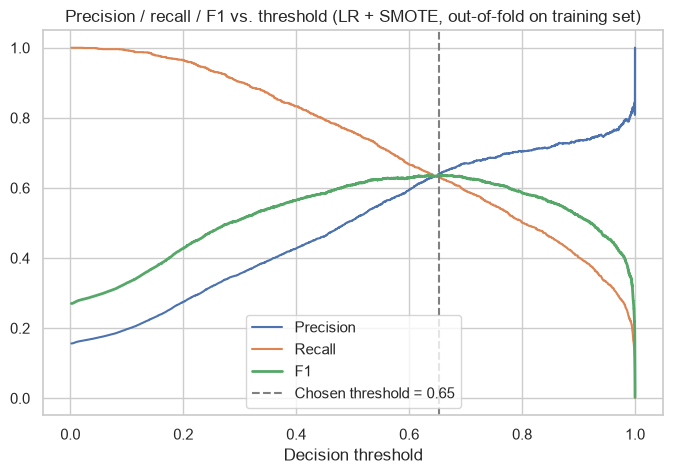

In [46]:
plt.figure(figsize=(8, 5))
plt.plot(thr, prec[:-1], label="Precision")
plt.plot(thr, rec[:-1], label="Recall")
plt.plot(thr, f1s, label="F1", linewidth=2)
plt.axvline(best_threshold, color="grey", linestyle="--", label=f"Chosen threshold = {best_threshold:.2f}")
plt.xlabel("Decision threshold")
plt.title(f"Precision / recall / F1 vs. threshold ({final_name}, out-of-fold on training set)")
plt.legend()
plt.show()

# **13. Final Evaluation**

,PR-AUC,ROC-AUC,Precision,Recall,F1,Accuracy
Model,,,,,,
LR + SMOTE @ 0.65,0.6636,0.9095,0.6481,0.6702,0.6589,0.8914


              precision    recall  f1-score   support

 No purchase       0.94      0.93      0.94      2059
    Purchase       0.65      0.67      0.66       382

    accuracy                           0.89      2441
   macro avg       0.79      0.80      0.80      2441
weighted avg       0.89      0.89      0.89      2441



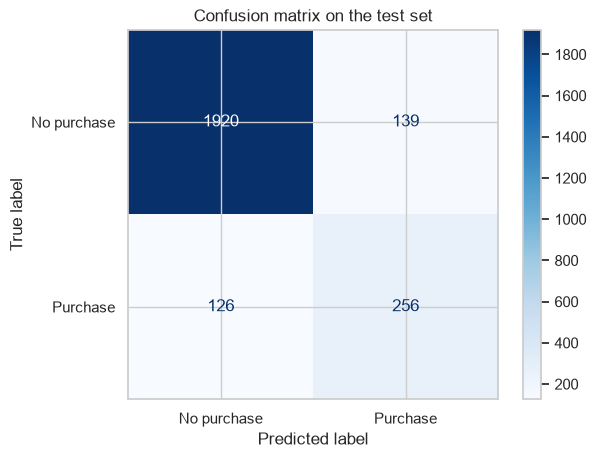

In [47]:
test_prob = final_model.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= best_threshold).astype(int)

final_row = evaluate(f"{final_name} @ {best_threshold:.2f}", y_test, test_prob, best_threshold)
display(pd.DataFrame([final_row]).set_index("Model").round(4))

print(classification_report(y_test, test_pred, target_names=["No purchase", "Purchase"]))

ConfusionMatrixDisplay.from_predictions(y_test, test_pred,
                                        display_labels=["No purchase", "Purchase"], cmap="Blues")
plt.title("Confusion matrix on the test set")
plt.show()

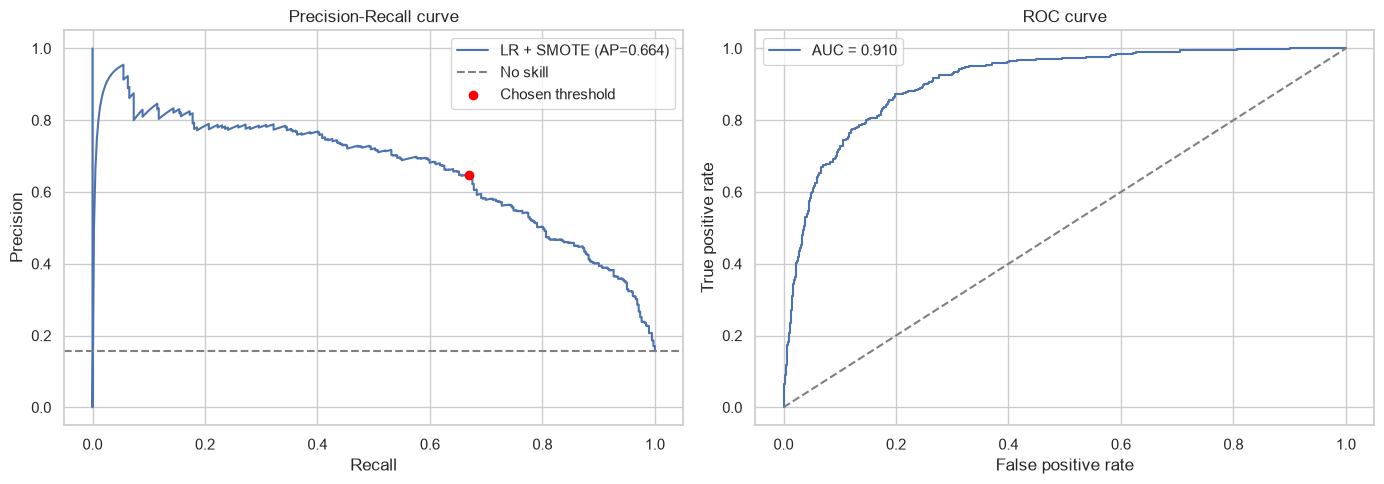

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

p, r, _ = precision_recall_curve(y_test, test_prob)
axes[0].plot(r, p, label=f"{final_name} (AP={average_precision_score(y_test, test_prob):.3f})")
axes[0].axhline(baseline_pr, color="grey", linestyle="--", label="No skill")
axes[0].scatter([recall_score(y_test, test_pred)], [precision_score(y_test, test_pred)],
                color="red", zorder=5, label="Chosen threshold")
axes[0].set_xlabel("Recall"); axes[0].set_ylabel("Precision")
axes[0].set_title("Precision-Recall curve"); axes[0].legend()

fpr, tpr, _ = roc_curve(y_test, test_prob)
axes[1].plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_test, test_prob):.3f}")
axes[1].plot([0, 1], [0, 1], "--", color="grey")
axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("True positive rate")
axes[1].set_title("ROC curve"); axes[1].legend()

plt.tight_layout()
plt.show()

# **14. What Drives Purchases? (Logistic Regression coefficients)**

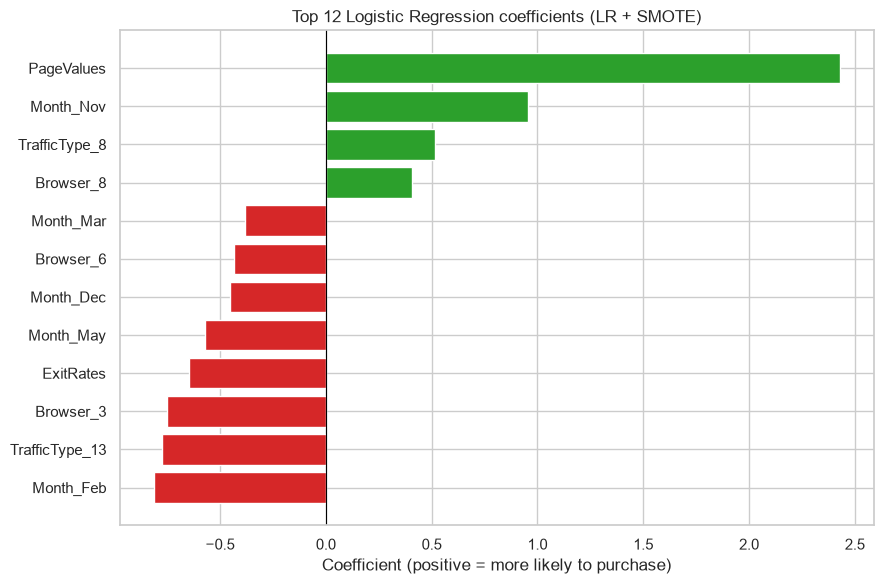

In [49]:
lr_pipe = fitted["LR + SMOTE"]
feature_names = lr_pipe.named_steps["prep"].get_feature_names_out()
coefs = pd.DataFrame({"Feature": feature_names,
                      "Coefficient": lr_pipe.named_steps["clf"].coef_[0]})
coefs["Feature"] = coefs["Feature"].str.replace(r"^(num|cat|bin)__", "", regex=True)
coefs["abs"] = coefs["Coefficient"].abs()
top = coefs.sort_values("abs", ascending=False).head(12).sort_values("Coefficient")

plt.figure(figsize=(9, 6))
colors = ["tab:red" if c < 0 else "tab:green" for c in top["Coefficient"]]
plt.barh(top["Feature"], top["Coefficient"], color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Coefficient (positive = more likely to purchase)")
plt.title("Top 12 Logistic Regression coefficients (LR + SMOTE)")
plt.tight_layout()
plt.show()

Numerical coefficients are on standardised features, so they are directly comparable in size. One-hot coefficients show the effect of that category relative to the rest.

# **15. Real-time Readiness Check**

`PageValues`, `BounceRates` and `ExitRates` are session-level statistics from web analytics. `PageValues` in particular is derived from pages that lead to a transaction, and these three features may only be fully known once a session ends. If so, they would not be available when the retailer needs to act.

To measure how much the model relies on them, retrain **without** these three features and compare.

In [50]:
late_features = ["PageValues", "BounceRates", "ExitRates"]
early_numeric = [c for c in numeric_cols if c not in late_features]

ablation = GridSearchCV(
    make_pipeline(LogisticRegression(max_iter=3000, random_state=RANDOM_STATE), numeric=early_numeric),
    param_grid={"clf__C": [0.01, 0.1, 1, 10, 100]},
    scoring="average_precision", cv=cv, n_jobs=-1)
ablation.fit(X_train.drop(columns=late_features), y_train)

abl_prob = ablation.best_estimator_.predict_proba(X_test.drop(columns=late_features))[:, 1]

comparison = pd.DataFrame([
    evaluate("LR + SMOTE (all features)", y_test, fitted["LR + SMOTE"].predict_proba(X_test)[:, 1]),
    evaluate("LR + SMOTE (without PageValues, BounceRates, ExitRates)", y_test, abl_prob),
]).set_index("Model")
display(comparison.round(4))

,PR-AUC,ROC-AUC,Precision,Recall,F1,Accuracy
Model,,,,,,
LR + SMOTE (all features),0.6636,0.9095,0.5093,0.7906,0.6195,0.8480
"LR + SMOTE (without PageValues, BounceRates, ExitRates)",0.3195,0.7279,0.2762,0.6832,0.3934,0.6702


# **16. Business Use of the Threshold**

In [51]:
# How precision and recall trade off at different cut-offs on the test set
rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, round(float(best_threshold), 2)]:
    pred = (test_prob >= t).astype(int)
    rows.append({"Threshold": t,
                 "Sessions flagged as likely buyers": int(pred.sum()),
                 "Precision": precision_score(y_test, pred, zero_division=0),
                 "Recall": recall_score(y_test, pred, zero_division=0)})
pd.DataFrame(rows).drop_duplicates("Threshold").sort_values("Threshold").round(3).reset_index(drop=True)

,Threshold,Sessions flagged as likely buyers,Precision,Recall
0,0.30,983,0.363,0.935
1,0.40,796,0.423,0.882
2,0.50,593,0.509,0.791
3,0.60,450,0.587,0.691
4,0.65,398,0.643,0.670
5,0.70,360,0.664,0.626
6,0.80,293,0.703,0.539


# **18. Save the Model**

In [52]:
import joblib

def best_threshold_for(model, Xtr, ytr):
    oof = cross_val_predict(model, Xtr, ytr, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
    p, r, t = precision_recall_curve(ytr, oof)
    f1 = 2 * p[:-1] * r[:-1] / (p[:-1] + r[:-1] + 1e-12)
    return float(t[np.argmax(f1)])

early_model = ablation.best_estimator_
early_threshold = best_threshold_for(early_model, X_train.drop(columns=late_features), y_train)

bundle = {
    "columns": list(X_train.columns),
    "full": {"model": final_model, "threshold": float(best_threshold), "name": final_name},
    "early": {"model": early_model, "threshold": early_threshold, "dropped": late_features},
    "numeric_ranges": {c: (0.0, float(np.ceil(X_train[c].quantile(0.995)))) for c in numeric_cols},
    "defaults": X_train.median(numeric_only=True).to_dict(),
    "categories": {c: sorted(X_train[c].unique().tolist()) for c in categorical_cols},
}
joblib.dump(bundle, "shopper_model.joblib")
print("Saved shopper_model.joblib | thresholds: full = %.2f, early = %.2f" % (best_threshold, early_threshold))


Saved shopper_model.joblib | thresholds: full = 0.65, early = 0.52
